# **PRÁCTICA 1**

## **California Housing**

In [1]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [2]:
# Cargar el conjunto de datos de California Housing
housing_data = fetch_california_housing()

# Separar características y etiquetas
X = housing_data.data
y = housing_data.target

# Dividir el conjunto de datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Escalar características
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [3]:
# Definir el modelo de la red neuronal con Keras
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)   # 1 salida porque es regresión
])

# Compilar el modelo
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['RootMeanSquaredError']
)

# Entrenar el modelo
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Evaluar el modelo en el conjunto de prueba
loss, rmse = model.evaluate(X_test_scaled, y_test, verbose=0)

print("MSE en test:", loss)
print("RMSE en test:", rmse)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - RootMeanSquaredError: 0.9211 - loss: 0.8485 - val_RootMeanSquaredError: 0.6928 - val_loss: 0.4800
Epoch 2/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - RootMeanSquaredError: 0.6428 - loss: 0.4133 - val_RootMeanSquaredError: 0.6422 - val_loss: 0.4124
Epoch 3/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 0.6091 - loss: 0.3710 - val_RootMeanSquaredError: 0.6311 - val_loss: 0.3983
Epoch 4/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 0.5972 - loss: 0.3567 - val_RootMeanSquaredError: 0.6239 - val_loss: 0.3892
Epoch 5/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 0.5892 - loss: 0.3472 - val_RootMeanSquaredError: 0.6175 - val_loss: 0.3812
Epoch 6/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 0.5874 - loss: 0.3451 - val_RootMeanSquaredError: 0.6058 - val_loss: 0.3670
Epoch 7/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 0.5820 - l

Para el problema California Housing se ha implementado una red neuronal densa orientada a regresión. La arquitectura elegida tiene dos capas ocultas con activación ReLU y una capa de salida con una sola neurona, adecuada para predecir un valor continuo. El modelo se ha entrenado con el optimizador Adam y la función de pérdida MSE, evaluándolo finalmente con RMSE sobre el conjunto de prueba. Esta configuración constituye una buena solución base, aunque posteriormente se podrían probar más neuronas, más capas o técnicas de regularización como dropout para comprobar si mejora el rendimiento y controlar mejor el sobreajuste.

## **Modelo Mejorado**

In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

# Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Modelo mejorado con regularización
model_reg = Sequential([
    Dense(128, activation='relu', kernel_regularizer=l2(0.001), input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),

    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),

    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),

    Dense(1)
])

# Compilación
model_reg.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['RootMeanSquaredError']
)

# Entrenamiento
history_reg = model_reg.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# Evaluación
loss_reg, rmse_reg = model_reg.evaluate(X_test_scaled, y_test, verbose=0)

print("MSE en test:", loss_reg)
print("RMSE en test:", rmse_reg)

Epoch 1/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - RootMeanSquaredError: 1.0096 - loss: 1.1520 - val_RootMeanSquaredError: 0.7063 - val_loss: 0.6207
Epoch 2/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 0.7215 - loss: 0.6342 - val_RootMeanSquaredError: 0.6562 - val_loss: 0.5368
Epoch 3/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 0.6827 - loss: 0.5664 - val_RootMeanSquaredError: 0.6439 - val_loss: 0.5105
Epoch 4/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 0.6582 - loss: 0.5242 - val_RootMeanSquaredError: 0.6473 - val_loss: 0.5059
Epoch 5/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 0.6472 - loss: 0.5019 - val_RootMeanSquaredError: 0.6233 - val_loss: 0.4681
Epoch 6/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 0.6337 - loss: 0.4781 - val_RootMeanSquaredError: 0.6216 - val_loss: 0.4594
Epoch 7/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.6

En esta segunda implementación se ha probado una arquitectura más robusta, incorporando distintas técnicas de regularización para mejorar la generalización del modelo. En concreto, se ha utilizado regularización L2 en las capas densas, Dropout para reducir la dependencia entre neuronas y Early Stopping para detener el entrenamiento cuando la pérdida de validación deja de mejorar

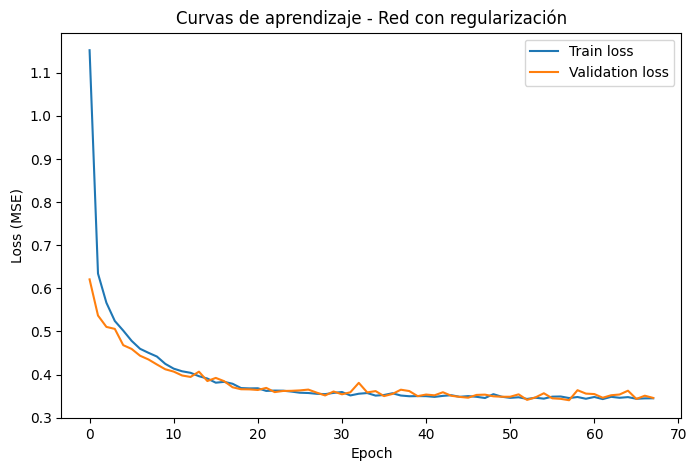

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history_reg.history['loss'], label='Train loss')
plt.plot(history_reg.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Curvas de aprendizaje - Red con regularización')
plt.legend()
plt.show()

In [8]:
print("RMSE modelo base:", rmse)
print("RMSE modelo regularizado:", rmse_reg)

RMSE modelo base: 0.5534945130348206
RMSE modelo regularizado: 0.5402653217315674


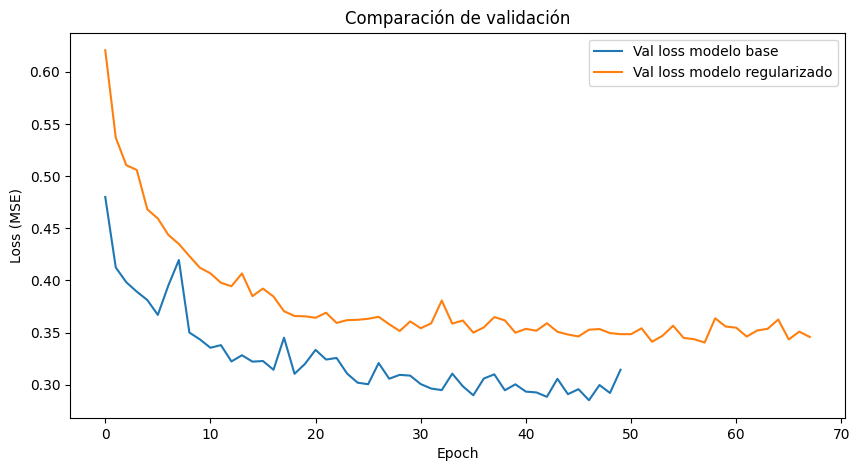

In [9]:
plt.figure(figsize=(10,5))

plt.plot(history.history['val_loss'], label='Val loss modelo base')
plt.plot(history_reg.history['val_loss'], label='Val loss modelo regularizado')

plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Comparación de validación')
plt.legend()
plt.show()

Al comparar el modelo base con el modelo regularizado, se observa una ligera mejora en el RMSE, pasando de 0.553 a 0.540. Aunque la diferencia no es muy grande, indica que las técnicas de regularización (L2, Dropout y Early Stopping) contribuyen a mejorar la capacidad de generalización del modelo. Este resultado sugiere que el modelo base ya presentaba un buen ajuste y no sufría un sobreajuste severo, por lo que el impacto de la regularización es moderado

## **Fashion MNIST**

In [15]:
import numpy as np
from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [16]:
# Cargar el conjunto de datos Fashion MNIST
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalizar las imágenes
X_train_normalized = X_train.astype('float32') / 255.0
X_test_normalized = X_test.astype('float32') / 255.0

# Redimensionar las imágenes a un vector unidimensional
X_train_flattened = X_train_normalized.reshape((X_train_normalized.shape[0], -1))
X_test_flattened = X_test_normalized.reshape((X_test_normalized.shape[0], -1))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [17]:
# Definir el modelo de la red neuronal con Keras
model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_flattened.shape[1],)),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# Compilar el modelo
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenar el modelo
history = model.fit(
    X_train_flattened,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

# Evaluar el modelo en el conjunto de prueba
loss, accuracy = model.evaluate(X_test_flattened, y_test)

print("Pérdida en el conjunto de prueba:", loss)
print("Precisión en el conjunto de prueba:", accuracy)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8187 - loss: 0.5139 - val_accuracy: 0.8571 - val_loss: 0.3984
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8624 - loss: 0.3797 - val_accuracy: 0.8709 - val_loss: 0.3562
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8762 - loss: 0.3397 - val_accuracy: 0.8782 - val_loss: 0.3431
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8830 - loss: 0.3184 - val_accuracy: 0.8815 - val_loss: 0.3378
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8896 - loss: 0.2977 - val_accuracy: 0.8695 - val_loss: 0.3747
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8923 - loss: 0.2858 - val_accuracy: 0.8836 - val_loss: 0.3275
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8987 - loss: 0.2698 - val_accuracy: 0.8744 - val_loss: 0.3573
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9042 - loss: 0.2596 - 

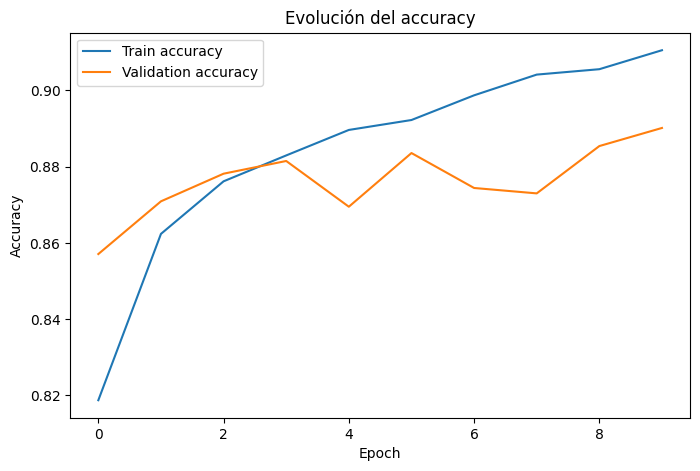

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Evolución del accuracy')
plt.legend()
plt.show()

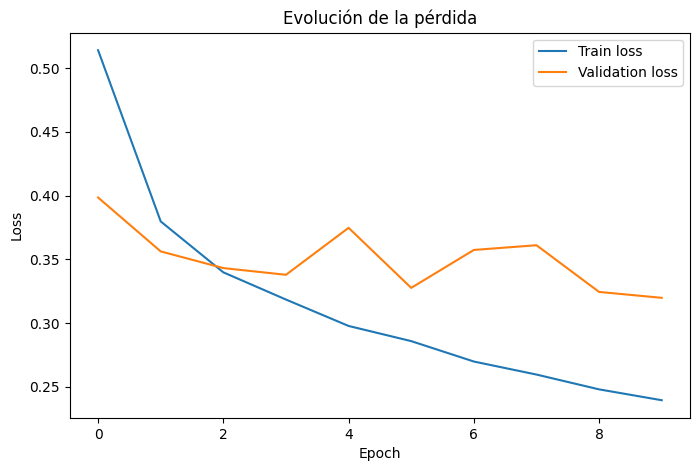

In [19]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Evolución de la pérdida')
plt.legend()
plt.show()

A partir de la evolución del entrenamiento, se observa que tanto el accuracy como el validation accuracy aumentan progresivamente a lo largo de los epochs, lo que indica que el modelo está aprendiendo correctamente. Además, la cercanía entre ambos valores sugiere que el modelo no presenta un sobreajuste significativo y generaliza adecuadamente sobre datos no vistos.

## **Modelo Mejorado**

In [20]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Definir el modelo mejorado
model_mejorado = Sequential([
    Dense(256, activation='relu', input_shape=(X_train_flattened.shape[1],)),
    Dropout(0.3),

    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(64, activation='relu'),

    Dense(10, activation='softmax')
])

# Compilar
model_mejorado.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenar
history_mejorado = model_mejorado.fit(
    X_train_flattened,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

# Evaluar
loss_mejorado, acc_mejorado = model_mejorado.evaluate(X_test_flattened, y_test)

print("Accuracy modelo base:", accuracy)
print("Accuracy modelo mejorado:", acc_mejorado)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.7758 - loss: 0.6139 - val_accuracy: 0.8432 - val_loss: 0.4317
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step - accuracy: 0.8351 - loss: 0.4564 - val_accuracy: 0.8585 - val_loss: 0.3904
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8472 - loss: 0.4177 - val_accuracy: 0.8677 - val_loss: 0.3619
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8559 - loss: 0.3932 - val_accuracy: 0.8677 - val_loss: 0.3659
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8610 - loss: 0.3759 - val_accuracy: 0.8714 - val_loss: 0.3582
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8671 - loss: 0.3624 - val_accuracy: 0.8737 - val_loss: 0.3414
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8705 - loss: 0.3512 - val_accuracy: 0.8724 - val_loss: 0.3546
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8755 - loss: 0.3406

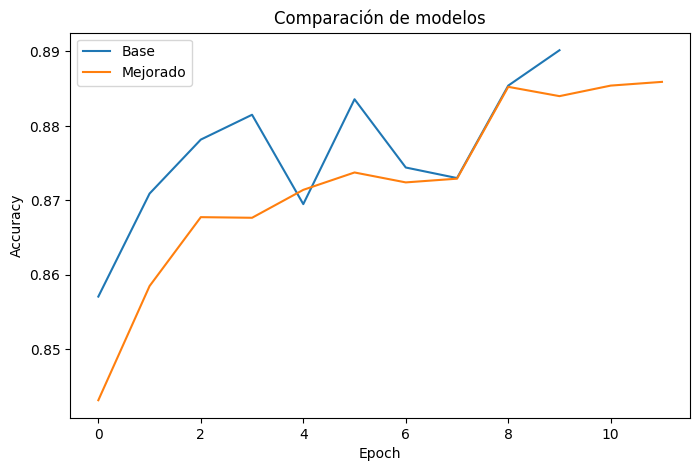

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['val_accuracy'], label='Base')
plt.plot(history_mejorado.history['val_accuracy'], label='Mejorado')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Comparación de modelos')
plt.legend()
plt.show()

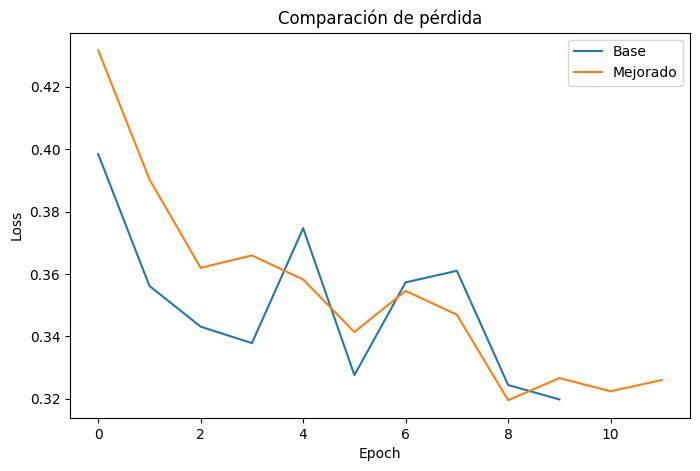

In [22]:
plt.figure(figsize=(8,5))
plt.plot(history.history['val_loss'], label='Base')
plt.plot(history_mejorado.history['val_loss'], label='Mejorado')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Comparación de pérdida')
plt.legend()
plt.show()

Al comparar el modelo base con el modelo mejorado, se observa que la introducción de técnicas de regularización como Dropout y Early Stopping no ha supuesto una mejora en el accuracy, obteniéndose incluso un rendimiento ligeramente inferior. Esto puede deberse a que el modelo base ya presentaba un buen ajuste y no sufría un sobreajuste significativo, por lo que la regularización reduce ligeramente la capacidad de aprendizaje del modelo. El uso de un valor relativamente alto de Dropout puede estar limitando la capacidad del modelo para aprender patrones complejos en los datos.

In [23]:
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Early Stopping más relajado
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Modelo mejorado
model_mejorado = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_flattened.shape[1],)),
    Dropout(0.2),

    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(10, activation='softmax')
])

# Compilar
model_mejorado.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenar
history_mejorado = model_mejorado.fit(
    X_train_flattened,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

# Evaluar
loss_mejorado, acc_mejorado = model_mejorado.evaluate(X_test_flattened, y_test)

print("Accuracy modelo base:", accuracy)
print("Accuracy modelo mejorado:", acc_mejorado)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.7827 - loss: 0.6125 - val_accuracy: 0.8434 - val_loss: 0.4267
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8392 - loss: 0.4415 - val_accuracy: 0.8593 - val_loss: 0.3812
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8534 - loss: 0.4024 - val_accuracy: 0.8634 - val_loss: 0.3768
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8624 - loss: 0.3755 - val_accuracy: 0.8562 - val_loss: 0.3880
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8670 - loss: 0.3621 - val_accuracy: 0.8749 - val_loss: 0.3503
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8731 - loss: 0.3488 - val_accuracy: 0.8776 - val_loss: 0.3349
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8758 - loss: 0.3376 - val_accuracy: 0.8799 - val_loss: 0.3319
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8813 - loss: 0.3237 -

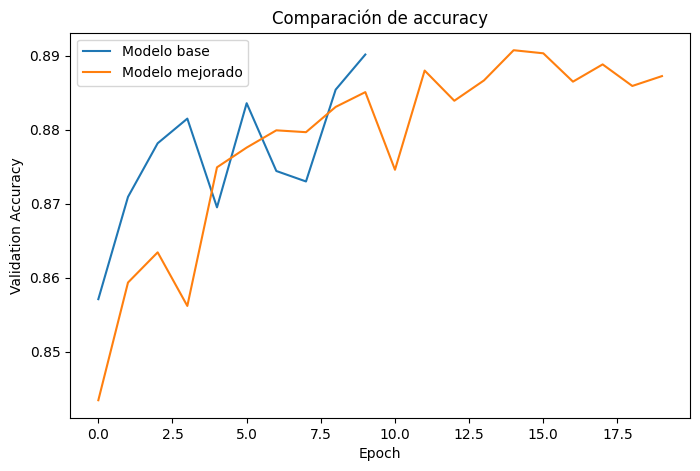

In [24]:
plt.figure(figsize=(8,5))
plt.plot(history.history['val_accuracy'], label='Modelo base')
plt.plot(history_mejorado.history['val_accuracy'], label='Modelo mejorado')

plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Comparación de accuracy')
plt.legend()
plt.show()

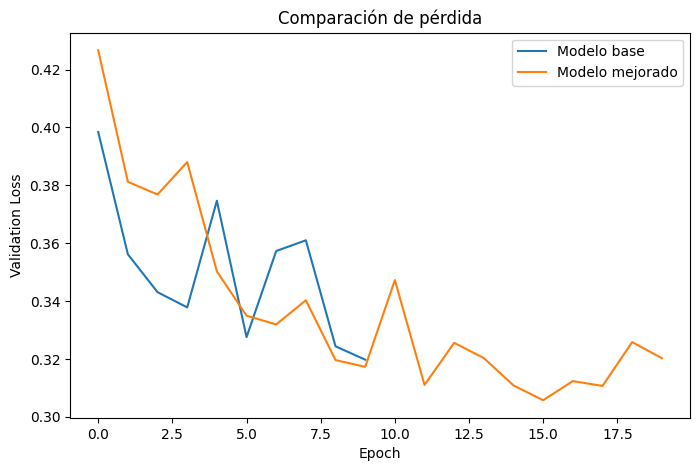

In [25]:
plt.figure(figsize=(8,5))
plt.plot(history.history['val_loss'], label='Modelo base')
plt.plot(history_mejorado.history['val_loss'], label='Modelo mejorado')

plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.title('Comparación de pérdida')
plt.legend()
plt.show()

Tras ajustar la arquitectura del modelo y reducir la intensidad de la regularización, se observa una ligera mejora en el rendimiento respecto al modelo base, pasando de una precisión de aproximadamente 0.879 a 0.882. Aunque la diferencia no es muy elevada, indica que una aplicación más equilibrada de técnicas como Dropout permite mejorar la capacidad de generalización sin perjudicar el aprendizaje. Además, la evolución del accuracy durante el entrenamiento muestra un comportamiento estable y sin indicios claros de sobreajuste, lo que confirma que el modelo es capaz de generalizar adecuadamente sobre datos no vistos

In [26]:
#hacemos matriz de confusion

import numpy as np

y_pred = model_mejorado.predict(X_test_flattened)
y_pred_classes = np.argmax(y_pred, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


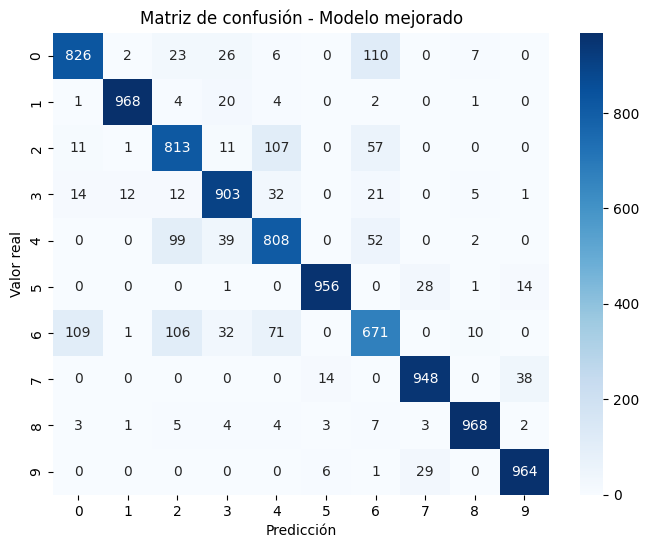

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - Modelo mejorado")

plt.show()

La matriz de confusión muestra que el modelo presenta un buen rendimiento general, ya que la mayoría de las predicciones correctas se concentran en la diagonal principal. Esto indica que el modelo es capaz de identificar adecuadamente la mayor parte de las clases. Sin embargo, se observan ciertos errores entre algunas categorías, donde el modelo tiende a confundir unas clases con otras. Estas confusiones son más frecuentes en aquellas clases que presentan características similares entre sí, lo cual dificulta su correcta diferenciación. Por otro lado, existen clases que el modelo identifica con mayor precisión, lo que sugiere que presentan rasgos más distintivos. En conjunto, el modelo muestra una buena capacidad de clasificación, aunque todavía presenta margen de mejora en la discriminación entre clases similares.